In [6]:

from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display


In [7]:

# 1. Define shared state
class AgentState(TypedDict):
    product: str
    details: str
    price: str
    availability: str
    final_result: str

In [8]:



# 2. First branch: Get product details
def get_product_details(state: AgentState):
    print("Getting product details...")

    return {
        "details": f"{state['product']} is an electronic product"
    }


# 3. Second branch: Check product price
def check_price(state: AgentState):
    print("Checking product price...")

    return {
        "price": "$500"
    }


# 4. Third branch: Check availability
def check_availability(state: AgentState):
    print("Checking product availability...")

    return {
        "availability": "In Stock"
    }


# 5. Combine all branch results
def combine_results(state: AgentState):
    print("Combining results...")

    return {
        "final_result": (
            f"Product: {state['product']}\n"
            f"Details: {state['details']}\n"
            f"Price: {state['price']}\n"
            f"Availability: {state['availability']}"
        )
    }


In [ ]:


# 6. Build workflow
builder = StateGraph(AgentState)

builder.add_node("get_details", get_product_details)
builder.add_node("check_price", check_price)
builder.add_node("check_availability", check_availability)
builder.add_node("combine", combine_results)


# 7. Multiple parallel branches These edges create fan-out.
builder.add_edge(START, "get_details")
builder.add_edge(START, "check_price")
builder.add_edge(START, "check_availability")


# 8. Fan-in + Synchronization:
# Wait for all three parallel nodes to complete before executing combine.
builder.add_edge("get_details", "combine")
builder.add_edge("check_price", "combine")
builder.add_edge("check_availability", "combine")

 # 9. Finish workflow
builder.add_edge("combine", END)


# 9. Compile workflow
graph = builder.compile()



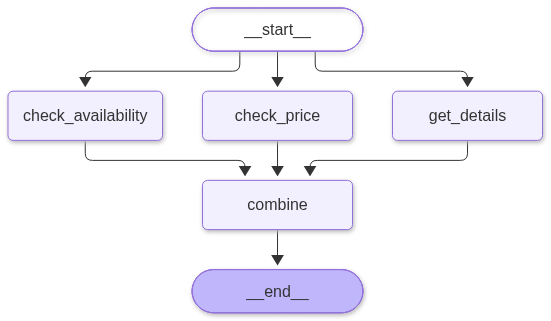

In [10]:
#Print Graph
display(
    Image(graph.get_graph().draw_mermaid_png())
)

In [11]:

# 10. Execute workflow
result = graph.invoke({
    "product": "Laptop"
})

print("\nFinal Output:")
print(result["final_result"])


Checking product availability...
Checking product price...
Getting product details...
Combining results...

Final Output:
Product: Laptop
Details: Laptop is an electronic product
Price: $500
Availability: In Stock
